# TP3 — Análisis multivariante del ecosistema de noticias (GDELT 2.0)

**Materia:** Ingeniería de Datos · **Datos:** eventos GDELT 2.0 publicados el **05/10/2026** (96 archivos `export.CSV`).

Preguntas de investigación:

1. **Perfil multivariante de eventos** — vectores de medias.
2. **Topología de cobertura mediática** — distancias entre perfiles.
3. **Estructura de correlación** — asociaciones entre variables.
4. **Compresión del ecosistema de noticias** — ACP: cuántas componentes y qué significan.

---

## Declaración de uso de Inteligencia Artificial

| Herramienta | Propósito |
|---|---|
| **Claude Opus 5.5** (Claude Code) | Organización del proyecto en carpetas (`data/raw`, `data/processed`, `src`, `notebooks`), código fuente de la ingesta, del almacén de datos, de la matriz de datos y de las funciones de análisis (medias, distancias, correlaciones, ACP, biplot) y armado de este notebook. En los ítems en los que la consigna pide un rol de tutor socrático, la IA dejó **preguntas guía** en lugar de la interpretación. Las preguntas fueron respondidas con ayuda de la IA y la participación y revisión del equipo. |

Las interpretaciones marcadas con ✍️ y las decisiones metodológicas señaladas con 🧭 son de elaboración propia.

---

## Organización del proyecto

```
TP3/
├── config.toml            # parámetros: fecha, umbral 'OTHER', variables, criterios del ACP
├── requirements.txt
├── data/
│   ├── raw/               # export.CSV.zip tal como los publica GDELT + tablas de códigos
│   └── processed/         # almacén SQLite, vista de análisis y matriz de datos (parquet)
├── src/                   # código fuente (ingesta, almacén, matriz, multivariante, acp)
│   └── sql/dw_schema.sql  # esquema estrella del TP2 extendido
└── notebooks/
    └── TP3.ipynb          # este notebook
```

Todo lo que está en `data/processed` se regenera con `python -m src.pipeline` (o con la primera celda de código de la Actividad 1).

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import acp, multivariante as mv
from src.config import cargar_config
from src.matriz import codificar_dummies, reducir_cardinalidad, tabla_cardinalidad, variables_continuas
from src.pipeline import ejecutar

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")

cfg = cargar_config(RAIZ / "config.toml")
print(f"Día analizado: {cfg.fecha} | umbral OTHER: {cfg.matriz['umbral_otros']:.0%}")

Día analizado: 2026-10-05 | umbral OTHER: 5%


# 1) Ingesta de datos

## 1.1 Organización: extensión del almacén de datos del TP2

El esquema estrella del TP2 (grano: una fila por noticia-evento) se extiende con lo que pide la consigna
(`src/sql/dw_schema.sql`):

| Requisito | Dónde queda en el almacén |
|---|---|
| Actores 1 y 2 | `DIM_ACTOR` con **rol doble** (`actor1_key` origen, `actor2_key` destino): código, nombre, país del actor y tipo (`Type1Code` + descripción CAMEO). Clave 0 = sin actor. |
| Tipo de interacción | **`DIM_TIPO_INTERACCION`** (nueva): `QuadClass` desglosada en los ejes cooperación/conflicto × verbal/material. La acción específica sigue en `DIM_CAMEO` (código, base y raíz). |
| Región del evento | `DIM_UBICACION` (geo de la acción): país FIPS 10-4 + nombre, ADM1, nombre completo, tipo de geocodificación, lat/long. Clave 0 = sin ubicación. |
| Tono e impacto Goldstein | Medidas no aditivas de `FACT_COBERTURA_EVENTO`: `avg_tone`, `goldstein_scale` (junto con `num_mentions`, `num_sources`, `num_articles`). |

La vista `v_eventos_analisis` aplana la estrella y es la única entrada del análisis multivariante.

La celda siguiente ejecuta la pipeline completa: descarga a `data/raw` (si los archivos ya están, los reutiliza),
construye el almacén y la matriz en `data/processed`.

In [2]:
salida = ejecutar(cfg)
eventos = salida["eventos"]

[1/4] Descargando export.CSV del 2026-10-05 -> data/raw/gdelt/20261005
      cache: 96
[2/4] Parseando archivos crudos


      105,481 eventos únicos
[3/4] Construyendo almacén de datos


      dim_tiempo                       6
      dim_actor                    5,147
      dim_cameo                      201
      dim_tipo_interaccion             4
      dim_ubicacion                6,192
      dim_medio                    3,818
      fact_cobertura_evento      105,481


[4/4] Construyendo matriz de datos
      matriz: 105,481 filas x 22 columnas
Listo en 1.5 s


In [3]:
# Consulta de control sobre la estrella: eventos, tono y Goldstein medios por tipo de interacción
with sqlite3.connect(cfg.ruta("almacen")) as con:
    control = pd.read_sql("""
        SELECT ti.descripcion               AS tipo_interaccion,
               COUNT(*)                     AS eventos,
               ROUND(AVG(f.goldstein_scale), 2) AS goldstein_medio,
               ROUND(AVG(f.avg_tone), 2)        AS tono_medio,
               SUM(f.num_articles)          AS articulos
        FROM fact_cobertura_evento f
        JOIN dim_tipo_interaccion ti ON ti.interaccion_key = f.interaccion_key
        GROUP BY ti.interaccion_key ORDER BY ti.interaccion_key""", con)
control

,tipo_interaccion,eventos,goldstein_medio,tono_medio,articulos
0,Cooperación verbal,65224,2.42,-0.97,298126
1,Cooperación material,12103,4.74,-1.99,59614
2,Conflicto verbal,13980,-3.48,-3.46,66526
3,Conflicto material,14174,-7.80,-4.79,65109


In [4]:
nombres_pais = eventos.dropna(subset=["pais_nombre"]).drop_duplicates("pais_accion").set_index("pais_accion")["pais_nombre"]
eventos.head()

,global_event_id,fecha_publicacion,actor1_code,actor1_tipo,actor2_code,actor2_tipo,tipo_interaccion,cameo_code,evento_raiz,pais_accion,pais_nombre,adm1_code,latitud,longitud,es_evento_raiz,goldstein_scale,avg_tone,num_mentions,num_sources,num_articles
0,1326293368,2026-10-05,NaN,SIN_ACTOR,ful,SIN_TIPO,Cooperación verbal,043,04 CONSULT,NI,Nigeria,NI00,9.53333,8.9000,0,2.8,-3.441296,10,1,10
1,1326293369,2026-10-05,NaN,SIN_ACTOR,ful,SIN_TIPO,Cooperación verbal,043,04 CONSULT,NI,Nigeria,NI49,9.16667,9.7500,0,2.8,-3.441296,5,1,5
2,1326293370,2026-10-05,IND,SIN_TIPO,NaN,SIN_ACTOR,Conflicto verbal,120,12 REJECT,IN,India,IN09,23.21670,72.6833,0,-4.0,-1.418440,2,1,2
3,1326293371,2026-10-05,ful,SIN_TIPO,NaN,SIN_ACTOR,Cooperación verbal,042,04 CONSULT,NI,Nigeria,NI00,9.53333,8.9000,0,1.9,-3.441296,10,1,10
4,1326293372,2026-10-05,ful,SIN_TIPO,NaN,SIN_ACTOR,Cooperación verbal,042,04 CONSULT,NI,Nigeria,NI49,9.16667,9.7500,0,1.9,-3.441296,5,1,5


## 1.2 Reducción de cardinalidad

Las categorías con frecuencia relativa **< 5 %** se agrupan como `'OTHER'` antes de codificar
(`src/matriz.py::reducir_cardinalidad`). Variables categóricas: tipo del actor 1, tipo del actor 2,
tipo de interacción (QuadClass) y código raíz CAMEO del evento.

In [5]:
cats_cfg = cfg.matriz["categoricas"]
cats_orig = eventos[cats_cfg].fillna("SIN_DATO")
cats_red = cats_orig.apply(reducir_cardinalidad, umbral=cfg.matriz["umbral_otros"], etiqueta=cfg.matriz["etiqueta_otros"])

tabla_cardinalidad(cats_orig, cats_red, cats_cfg)

,categorias_originales,categorias_finales,pct_filas_en_OTHER
variable,,,
actor1_tipo,33,4,29.66
actor2_tipo,33,4,23.60
tipo_interaccion,4,4,0.00
evento_raiz,20,8,25.81


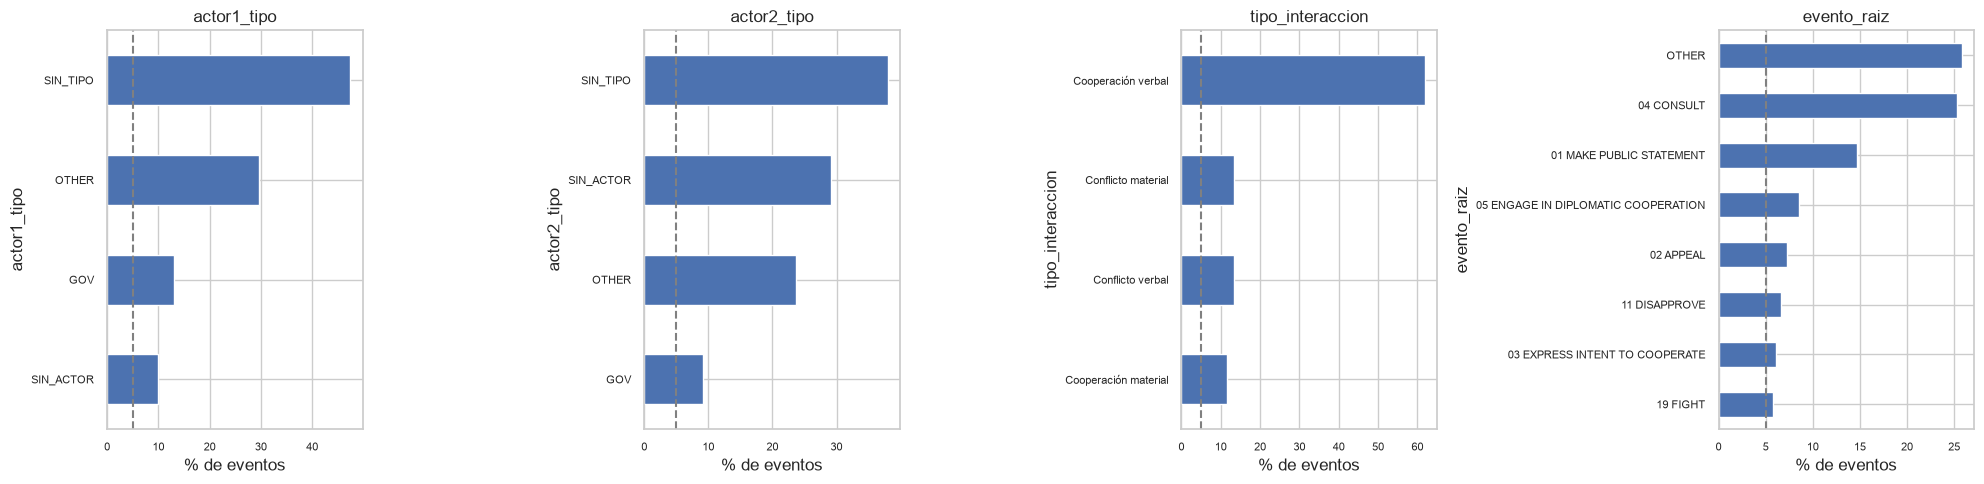

In [6]:
fig, axes = plt.subplots(1, len(cats_cfg), figsize=(20, 5))
for ax, c in zip(axes, cats_cfg):
    (100 * cats_red[c].value_counts(normalize=True)).sort_values().plot.barh(ax=ax, color="#4C72B0")
    ax.axvline(100 * cfg.matriz["umbral_otros"], ls="--", color="gray")
    ax.set_title(c); ax.set_xlabel("% de eventos"); ax.tick_params(labelsize=8)
plt.tight_layout()

> 🧭 **Guía (a completar por el equipo)** — la consigna pide que en este punto la IA no dé la respuesta directa.

- Mirá la columna `pct_filas_en_OTHER`. ¿`OTHER` quedó como una categoría "marginal" o terminó siendo de las más grandes en alguna variable? ¿Qué implica eso para interpretar luego su media o su carga?
- `SIN_TIPO` y `SIN_ACTOR` superaron el umbral. ¿Representan la misma ausencia de información? (Pista: ¿qué tipo de actor tiene un evento cuyo actor es un país, p. ej. `USA`?)
- `tipo_interaccion` no tiene ninguna categoría por debajo del 5 %. ¿Por qué no se generó `OTHER` y qué cambia eso para elegir la categoría de referencia en el paso siguiente?
- Si en lugar de 5 % usaran 1 %, ¿cuántas columnas tendría la matriz? ¿Qué ganarían y qué perderían en el ACP?


✍️ **Interpretación del equipo:** 
- OTHER Termino siendo de las categorias mas grandes. en evento_raiz: es la primera (25,8 %), por encima de 04 CONSULT. En actor1_tipo: es la segunda (29,7 %). Y en actor2_tipo: es la tercera (23,6 %).
- No, SIN_ACTOR: GDELT no identificó ningún actor. Es una ausencia estructural, típica del actor 2 en eventos con un solo actor (29 % de los casos). SIN_TIPO: el actor existe pero no tiene Type1Code. Son sobre todo actores codificados solo por país (USA, ISR) o entidades sin un rol asignado. Es información real ("el actor es un Estado o país genérico"), no un faltante.
- Sus 4 categorías superan el 5 % (la menor es Cooperación material, con 11,5 %), así que no se agrupa nada. Sin OTHER, la referencia pasa a ser la moda, Cooperación verbal (61,8 %). Entonces las dummies de esta variable se leen como contraste contra la interacción "típica", mientras que en las demás variables se leen contra un grupo residual. La referencia no es homogénea entre variables, y eso hay que tenerlo en cuenta al comparar sus coeficientes o cargas.
- Se gana: OTHER deja de mezclar cooperación con conflicto. Por ejemplo, 17 COERCE (4,9 %), 07 PROVIDE AID y 18 ASSAULT pasan a tener columna propia, y los perfiles son más interpretables. Se pierde: se agregan muchas dummies raras y casi independientes. Al estandarizarlas, cada una pesa lo mismo que una variable continua, así que inflan la dimensionalidad y el ACP comprime todavía peor. Es justo la "inflación de dimensiones" que la consigna quiere evitar.

## 1.3 Variables indicadoras (dummy)

Cada variable categórica reducida se transforma en indicadoras 0/1 (`src/matriz.py::codificar_dummies`).
Por cada variable se descarta la indicadora de una **categoría de referencia**: `OTHER` cuando existe y,
si no existe, la categoría más frecuente.

In [7]:
dummies, referencias = codificar_dummies(cats_red, cats_cfg, cfg.matriz["referencia_dummy"] or None)
print("Categoría de referencia descartada por variable:")
for var, ref in referencias.items():
    print(f"  {var:<18} -> {ref}")
print(f"\nIndicadoras generadas: {dummies.shape[1]}")
dummies.head()

Categoría de referencia descartada por variable:
  actor1_tipo        -> OTHER
  actor2_tipo        -> OTHER
  tipo_interaccion   -> Cooperación verbal
  evento_raiz        -> OTHER

Indicadoras generadas: 16


,actor1_tipo=GOV,actor1_tipo=SIN_ACTOR,actor1_tipo=SIN_TIPO,actor2_tipo=GOV,actor2_tipo=SIN_ACTOR,actor2_tipo=SIN_TIPO,tipo_interaccion=Conflicto material,tipo_interaccion=Conflicto verbal,tipo_interaccion=Cooperación material,evento_raiz=01 MAKE PUBLIC STATEMENT,evento_raiz=02 APPEAL,evento_raiz=03 EXPRESS INTENT TO COOPERATE,evento_raiz=04 CONSULT,evento_raiz=05 ENGAGE IN DIPLOMATIC COOPERATION,evento_raiz=11 DISAPPROVE,evento_raiz=19 FIGHT
0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0
1,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0
2,0,0,1,0,1,0,0,1,0,0,0,0,0,0,0,0
3,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0
4,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0


> 🧭 **Guía (a completar por el equipo)** — la consigna pide que en este punto la IA no dé la respuesta directa.

- ¿Qué pasaría con la matriz si se conservaran **todas** las indicadoras de una variable? Sumen las columnas de una misma variable fila por fila: ¿qué obtienen? ¿Qué le hace eso a la matriz de covarianzas?
- La referencia de `tipo_interaccion` es *Cooperación verbal*. Con esa elección, ¿cómo se lee la media de `tipo_interaccion=Conflicto material` en un país?
- Spoiler para el ACP: aun descartando referencias, el último autovalor les va a dar ≈ 0. Revisen en el codebook cómo se **define** `QuadClass` a partir de `EventRootCode`. ¿Hay alguna combinación lineal exacta entre las indicadoras de `tipo_interaccion` y las de `evento_raiz`? ¿Conviene dejar ambas variables?


✍️ **Interpretación del equipo:** 
- Las dummies de una misma variable suman exactamente 1 en cada fila, porque cada evento cae en una sola categoría. Esa suma es idéntica a la columna constante, así que hay colinealidad perfecta (la "trampa de las variables dummy"). Al centrar los datos, esas columnas suman 0, y la matriz de covarianzas queda singular: determinante 0, sin inversa y con un autovalor nulo por cada variable categórica.
- Es la proporción de eventos de ese país que son conflicto material: 13,4 % global, 23,6 % en Israel, 17,4 % en Rusia y 7,5 % en Canadá. La referencia, Cooperación verbal, no tiene columna, pero se recupera como 1 menos la suma de las otras tres: 61,8 % global, 49,6 % en Israel y 69,5 % en Canadá. Por eso no se pierde información. Una media alta de conflicto material implica, mecánicamente, menos cooperación verbal, que es la interacción "de base".
- Porque GDELT define la QuadClass a partir del código raíz CAMEO: los códigos 01 a 05 son siempre cooperación verbal, del 06 al 08 cooperación material, del 09 al 13 conflicto verbal y del 14 al 20 conflicto material. Como los códigos 01 a 05 tienen dummy propia, la suma de esas cinco columnas coincide exactamente con la proporción de cooperación verbal, que se obtiene a partir de las otras tres dummies de tipo_interaccion. Esa dependencia lineal exacta entre las dos variables es lo que hace que la última componente tenga varianza 0. Descartar una categoría de referencia no la evita, porque la redundancia está entre las dos variables y no dentro de una. Conviene mantener ambas.

## 1.4 Matriz de datos

Matriz integrada **X** (n × p): variables continuas + `es_evento_raiz` + indicadoras. Los conteos
(`num_mentions`, `num_sources`, `num_articles`) entran como `log(1 + x)` por su fuerte asimetría (`config.toml → log1p`).

In [8]:
X = salida["matriz"]
grupo = eventos.set_index("global_event_id").loc[X.index, cfg.matriz["grupo"]]
print(f"X: {X.shape[0]:,} eventos x {X.shape[1]} variables")
X.describe().T.round(3)

X: 105,481 eventos x 22 variables


,count,mean,std,min,25%,50%,75%,max
goldstein_scale,105481.0,0.530,4.574,-10.000,-2.000,1.900,3.400,10.000
avg_tone,105481.0,-1.931,4.081,-31.111,-4.579,-1.968,0.860,17.073
log_num_mentions,105481.0,1.556,0.603,0.693,1.099,1.609,1.946,5.198
log_num_sources,105481.0,0.709,0.113,0.693,0.693,0.693,0.693,2.708
log_num_articles,105481.0,1.547,0.591,0.693,1.099,1.609,1.946,4.949
es_evento_raiz,105481.0,0.537,0.499,0.000,0.000,1.000,1.000,1.000
actor1_tipo=GOV,105481.0,0.130,0.336,0.000,0.000,0.000,0.000,1.000
actor1_tipo=SIN_ACTOR,105481.0,0.099,0.299,0.000,0.000,0.000,0.000,1.000
actor1_tipo=SIN_TIPO,105481.0,0.475,0.499,0.000,0.000,0.000,1.000,1.000
actor2_tipo=GOV,105481.0,0.092,0.289,0.000,0.000,0.000,0.000,1.000


,asimetría cruda,asimetría log1p
num_mentions,7.3,0.36
num_sources,16.0,9.63
num_articles,5.7,0.30


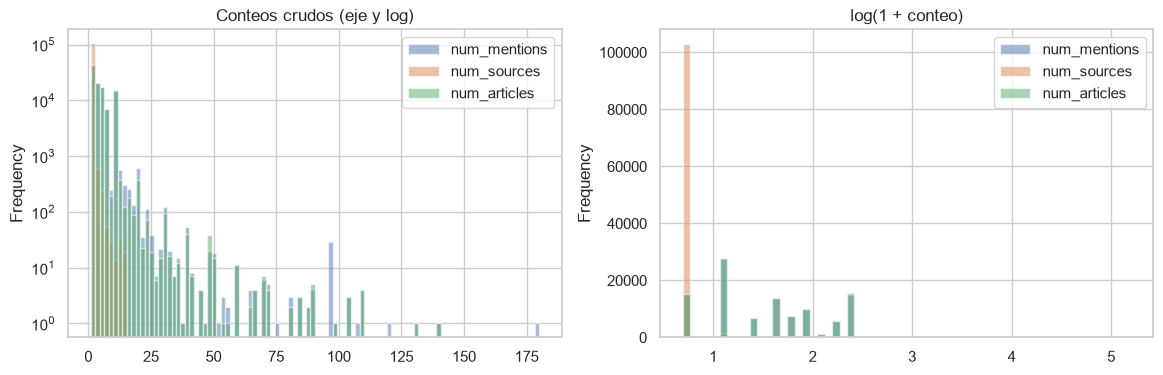

In [9]:
crudos = eventos[["num_mentions", "num_sources", "num_articles"]]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
crudos.plot.hist(bins=100, alpha=0.5, ax=axes[0], logy=True, title="Conteos crudos (eje y log)")
np.log1p(crudos).plot.hist(bins=60, alpha=0.5, ax=axes[1], title="log(1 + conteo)")
crudos.skew().round(1).to_frame("asimetría cruda").join(np.log1p(crudos).skew().round(2).rename("asimetría log1p"))

> 🧭 **Guía (a completar por el equipo)** — la consigna pide que en este punto la IA no dé la respuesta directa.

- Comparen las escalas de `goldstein_scale` (−10 a 10), `avg_tone`, los conteos y las indicadoras (0/1). Si calcularan distancias o un ACP **sin** estandarizar, ¿qué variable dominaría?
- ¿Qué significa la media de una columna indicadora? ¿Y su desvío estándar? ¿Qué le pasa al desvío de una indicadora muy rara (p ≈ 0.05) cuando se estandariza?
- ¿Tiene sentido aplicar log a los conteos? ¿Qué supuesto del ACP / de la correlación de Pearson se busca respetar?


✍️ **Interpretación del equipo:** 
- Dominarían goldstein_scale y avg_tone, que tienen desvíos de 4,6 y 4,1. Entre las dos concentran más del 90 % de la varianza total de la matriz. Las dummies y los conteos en logaritmo tienen varianzas menores a 0,4. Las distancias y el ACP sin estandarizar casi solo reflejarían Goldstein y tono, y la primera componente sería básicamente Goldstein. Al estandarizar, cada variable pasa a aportar en unidades de su propia dispersión.
- La media de una dummy es la proporción de eventos con esa categoría. Su desvío depende solo de esa proporción: es máximo cuando la categoría está en la mitad de los eventos y se achica cuando es rara. Con una proporción cercana al 5 %, el desvío ronda 0,22. Al estandarizar, los eventos que tienen la categoría pasan a valer alrededor de 4,4 y los que no la tienen, alrededor de −0,2. Así, cada aparición de una categoría rara se convierte en un valor extremo, aparecen atípicos artificiales y esa categoría termina pesando en el ACP lo mismo que una variable continua, aunque afecte a muy pocos eventos.
- Sí. Los conteos son muy asimétricos: la mayoría de los eventos tiene una o pocas menciones y unos pocos llegan a más de cien. Tanto la correlación de Pearson como el ACP se basan en varianzas y covarianzas, que son sensibles a valores extremos y suponen relaciones lineales. Con el logaritmo, la asimetría de menciones y artículos baja de alrededor de 6 o 7 a casi 0,3, así que unos pocos eventos virales ya no definen la estructura. En num_sources el logaritmo ayuda mucho menos (la asimetría sigue cerca de 10), porque casi todos los eventos tienen una sola fuente. En la práctica esa variable se comporta como binaria.

# 2) Descripción multivariante

## 2.1 Vectores de medias

Vector de medias global $\bar{\mathbf{x}} = \frac{1}{n}\sum_i \mathbf{x}_i$ y un vector de medias por país
(país de la acción, `ActionGeo_CountryCode`, códigos FIPS 10-4). Se toman los 12 países con más eventos
(`config.toml → top_paises`). Los eventos sin geocodificación (`SIN_UBICACION`) cuentan para el global pero no como país.

In [10]:
paises = mv.paises_principales(grupo, cfg.multivariante["top_paises"], cfg.multivariante["min_eventos_pais"])
medias = mv.vectores_medias(X, grupo, paises)

pd.DataFrame({"pais": nombres_pais.reindex(paises).values,
              "eventos": grupo.value_counts().reindex(paises).values}, index=paises).T

,US,IN,UK,NI,IS,RS,CA,CH,IR,AS,PK,SA
pais,United States,India,United Kingdom,Nigeria,Israel,Russia,Canada,China,Iran,Australia,Pakistan,Saudi Arabia
eventos,29620,6748,6342,4912,3994,2553,2252,2243,2129,1955,1645,1606


In [11]:
medias.round(3)

,goldstein_scale,avg_tone,log_num_mentions,log_num_sources,log_num_articles,es_evento_raiz,actor1_tipo=GOV,actor1_tipo=SIN_ACTOR,actor1_tipo=SIN_TIPO,actor2_tipo=GOV,actor2_tipo=SIN_ACTOR,actor2_tipo=SIN_TIPO,tipo_interaccion=Conflicto material,tipo_interaccion=Conflicto verbal,tipo_interaccion=Cooperación material,evento_raiz=01 MAKE PUBLIC STATEMENT,evento_raiz=02 APPEAL,evento_raiz=03 EXPRESS INTENT TO COOPERATE,evento_raiz=04 CONSULT,evento_raiz=05 ENGAGE IN DIPLOMATIC COOPERATION,evento_raiz=11 DISAPPROVE,evento_raiz=19 FIGHT
perfil,,,,,,,,,,,,,,,,,,,,,,
GLOBAL,0.530,-1.931,1.556,0.709,1.547,0.537,0.130,0.099,0.475,0.092,0.292,0.380,0.134,0.133,0.115,0.146,0.072,0.061,0.253,0.085,0.066,0.058
US,0.487,-2.018,1.521,0.707,1.513,0.549,0.097,0.119,0.432,0.069,0.339,0.312,0.144,0.127,0.123,0.150,0.079,0.058,0.244,0.076,0.070,0.053
IN,0.369,-1.805,1.646,0.702,1.636,0.579,0.164,0.123,0.275,0.119,0.397,0.208,0.112,0.179,0.121,0.125,0.084,0.066,0.243,0.070,0.074,0.039
UK,0.496,-1.929,1.562,0.726,1.550,0.518,0.118,0.109,0.483,0.075,0.308,0.391,0.126,0.144,0.120,0.160,0.068,0.062,0.239,0.081,0.067,0.047
NI,0.434,-1.498,1.502,0.695,1.495,0.562,0.218,0.082,0.409,0.163,0.298,0.308,0.116,0.132,0.106,0.209,0.086,0.040,0.207,0.103,0.059,0.054
IS,-1.059,-3.797,1.457,0.709,1.448,0.439,0.132,0.067,0.549,0.090,0.194,0.503,0.236,0.180,0.089,0.139,0.053,0.041,0.170,0.092,0.087,0.112
RS,-0.300,-4.942,1.469,0.707,1.462,0.445,0.177,0.048,0.561,0.112,0.171,0.514,0.174,0.156,0.114,0.163,0.061,0.055,0.231,0.044,0.081,0.095
CA,1.336,-0.120,1.693,0.711,1.678,0.530,0.119,0.115,0.447,0.077,0.373,0.322,0.075,0.093,0.137,0.186,0.090,0.082,0.243,0.095,0.047,0.025
CH,1.048,-1.955,1.518,0.718,1.503,0.473,0.132,0.070,0.570,0.108,0.198,0.506,0.092,0.140,0.141,0.143,0.060,0.049,0.294,0.081,0.088,0.021


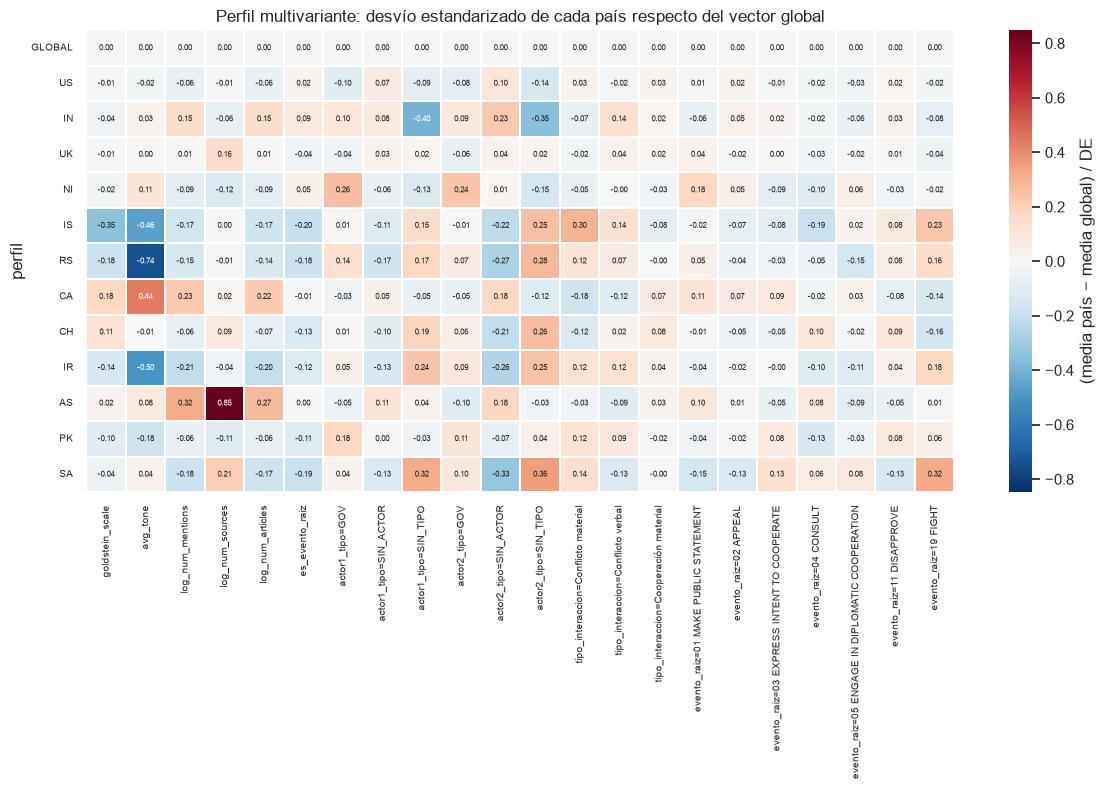

In [12]:
mv.heatmap_desvios_medias(medias, X);

> 🧭 **Guía (a completar por el equipo)** — la consigna pide que en este punto la IA no dé la respuesta directa.

**Pregunta 1 — Perfil multivariante.** Usen el mapa de desvíos estandarizados (cada celda = cuántos desvíos estándar se aleja la media del país de la global).

- ¿Qué países se apartan del perfil global en las mismas variables y en el mismo sentido? ¿Qué tienen en común esas variables (tono, Goldstein, conflicto material, `FIGHT`)?
- Un país con tono medio más negativo, ¿también tiene Goldstein más bajo? ¿Es esperable dado cómo se construye cada medida (una sale del texto del artículo, la otra del código CAMEO)?
- ¿Hay países que se distinguen más por **quiénes** participan (tipos de actor) que por **qué** pasa (tipo de interacción)?
- Recuerden que con n ≈ 100 000 cualquier diferencia de medias es "significativa": ¿qué magnitud de desvío consideran relevante?


✍️ **Interpretación del equipo:** 
- Israel, Rusia e Irán se apartan juntos, y en menor medida Arabia Saudita y Pakistán. Tienen tono más negativo, Goldstein más bajo, más conflicto material y más FIGHT. Canadá se aparta en el sentido opuesto en esas mismas variables. Las cuatro variables miden lo mismo de fondo: el grado de conflicto u hostilidad del evento. No son cuatro rasgos independientes sino una sola dimensión, conflicto contra cooperación, vista desde distintos ángulos.
- En general sí: entre los 12 países, el tono medio y el Goldstein medio van muy de la mano. Pero no es una relación exacta:
    - Rusia tiene el tono más negativo de todos y, aun así, un Goldstein menos extremo que Israel.
    - China tiene un Goldstein alto con un tono promedio.
Es esperable que coincidan solo en parte. Goldstein sale del código CAMEO, o sea, del tipo de acción y su impacto teórico. El tono sale del texto del artículo, así que también refleja cómo el medio encuadra la noticia. Cuando la agenda está dominada por el conflicto, las dos medidas convergen; el encuadre mediático puede separarlas.
- Sí:
    - India: su tono y su Goldstein son casi los globales. Lo que la distingue es que tiene muchos menos actores sin tipo, es decir, más actores con un rol explícito.
    - Nigeria: se distingue por una mayor presencia de actores gubernamentales.
    - China y Arabia Saudita: tienen más actores 2 sin tipo, típicos de una cobertura de Estado a Estado.

Australia es un tercer caso: no se distingue ni por quién ni por qué, sino por cuánto se cubre, porque sus eventos tienen muchas más fuentes.
- Con esa n, cualquier diferencia es estadísticamente significativa, así que hay que mirar el tamaño del efecto. Como criterio tomamos el desvío estandarizado: menos de 0,2 desvíos se considera despreciable y alrededor de 0,5 ya es una diferencia sustantiva. Con ese criterio:
    - Estados Unidos, Reino Unido y Pakistán tienen prácticamente el perfil global.
    - Las diferencias relevantes son el tono de Rusia (−0,74), las fuentes de Australia (+0,85), el tono de Irán e Israel (alrededor de −0,5) y el de Canadá (+0,44), y los tipos de actor en India (alrededor de −0,4).

### Distancias entre vectores de medias

Se usan dos métricas sobre los 13 vectores (global + 12 países):

- **Euclídea estandarizada**: cada variable dividida por su desvío global, para que ninguna domine por su escala.
- **Mahalanobis** con la covarianza global de **X**: además descuenta la redundancia entre variables correlacionadas
  (p. ej. menciones y artículos cuentan casi lo mismo). Se usa la pseudo-inversa porque la covarianza es singular (ver 1.3).

In [13]:
D_euc = mv.matriz_distancias(medias, X, "euclidea_std")
D_mah = mv.matriz_distancias(medias, X, "mahalanobis")

pd.DataFrame({"euclídea estandarizada": D_euc["GLOBAL"], "Mahalanobis": D_mah["GLOBAL"]}) \
  .drop("GLOBAL").sort_values("Mahalanobis").round(3).rename_axis("distancia al vector GLOBAL")

,euclídea estandarizada,Mahalanobis
distancia al vector GLOBAL,,
UK,0.203,0.208
US,0.267,0.287
PK,0.430,0.385
CH,0.524,0.463
NI,0.527,0.480
CA,0.696,0.564
IN,0.679,0.601
IS,0.891,0.658
IR,0.822,0.717


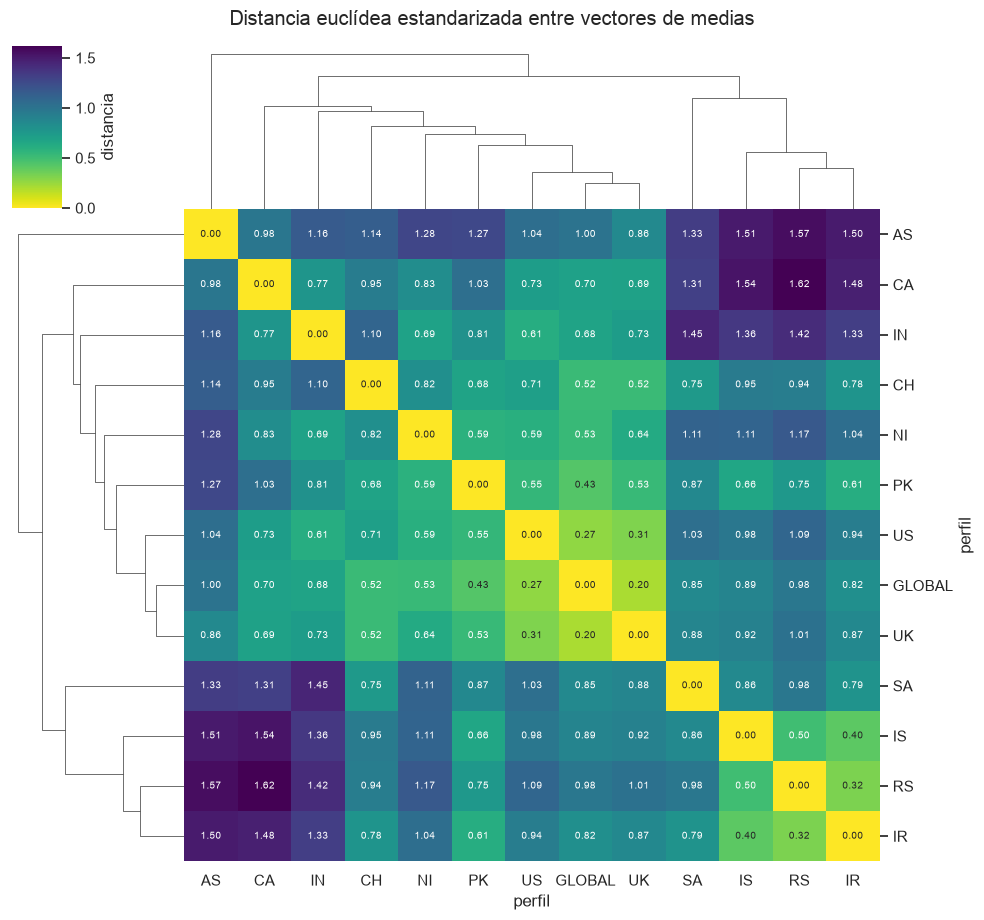

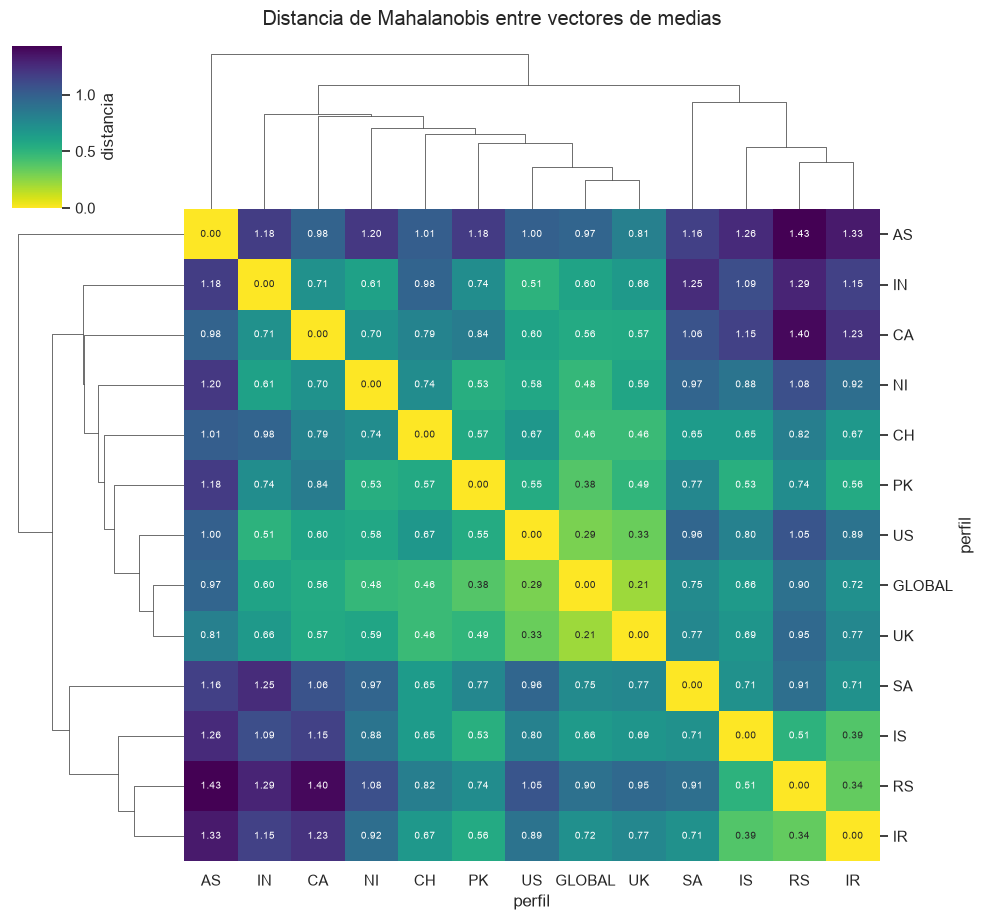

In [14]:
mv.clustermap_distancias(D_euc, "Distancia euclídea estandarizada entre vectores de medias");
mv.clustermap_distancias(D_mah, "Distancia de Mahalanobis entre vectores de medias");

In [15]:
for nombre, D in [("euclídea estandarizada", D_euc), ("Mahalanobis", D_mah)]:
    cerca, lejos = mv.pares_extremos(D, k=5)
    print(f"--- {nombre} ---")
    display(pd.concat({"más similares": cerca, "más disímiles": lejos}, axis=1).round(3))

--- euclídea estandarizada ---


más similares                    más disímiles                   
       perfil_a perfil_b distancia      perfil_a perfil_b distancia
0            US       UK     0.313            RS       CA     1.618
1            RS       IR     0.321            RS       AS     1.566
2            IS       IR     0.405            IS       CA     1.536
3            IS       RS     0.496            IS       AS     1.509
4            UK       CH     0.522            IR       AS     1.502

--- Mahalanobis ---


más similares                    más disímiles                   
       perfil_a perfil_b distancia      perfil_a perfil_b distancia
0            US       UK     0.329            RS       AS     1.430
1            RS       IR     0.342            RS       CA     1.402
2            IS       IR     0.387            IR       AS     1.332
3            UK       CH     0.463            IN       RS     1.286
4            UK       PK     0.492            IS       AS     1.258

In [16]:
# ¿Qué variables explican cada distancia? (% de la distancia euclídea² aportado por cada variable)
cerca, lejos = mv.pares_extremos(D_euc, k=1)
pares_a_explicar = [(cerca.perfil_a[0], cerca.perfil_b[0]), (lejos.perfil_a[0], lejos.perfil_b[0]),
                    ("GLOBAL", D_euc["GLOBAL"].drop("GLOBAL").idxmax())]
pd.concat({f"{a} vs {b}": mv.contribucion_distancia(medias, X, a, b, k=6).reset_index()
           .set_axis(["variable", "% de d²"], axis=1) for a, b in pares_a_explicar}, axis=1)

US vs UK                       RS vs CA                   GLOBAL vs AS        
                variable % de d²               variable % de d²               variable % de d²
0        log_num_sources    28.9               avg_tone    53.3        log_num_sources    71.7
1   actor2_tipo=SIN_TIPO    27.3  actor2_tipo=SIN_ACTOR     7.5       log_num_mentions     9.9
2   actor1_tipo=SIN_TIPO    10.9   actor2_tipo=SIN_TIPO     5.9       log_num_articles     7.4
3  actor2_tipo=SIN_ACTOR     4.8       log_num_mentions     5.3  actor2_tipo=SIN_ACTOR     3.4
4       log_num_mentions     4.7       log_num_articles     5.1  actor1_tipo=SIN_ACTOR     1.3
5       log_num_articles     4.0        goldstein_scale     4.9        actor2_tipo=GOV     1.1

**Pregunta 2 — Topología de cobertura mediática** (datos del 05/10/2026).

- **Perfiles más parecidos al global:** Reino Unido (0,20) y Estados Unidos (0,27) son los vectores más cercanos al global con ambas métricas.
  En el caso de EE. UU. es en parte mecánico: concentra ~28 % de los eventos, así que "arrastra" la media global hacia sí.
  El par **EE. UU.–Reino Unido** es el más similar de todos (0,31); lo poco que los separa es la cobertura (`log_num_sources`) y la
  proporción de actores sin tipo, no el tipo de interacción.
- **Un bloque de conflicto:** **Rusia, Irán e Israel** forman un grupo compacto (RS–IR 0,32; IS–IR 0,40; IS–RS 0,50), al que el dendrograma
  agrega a Arabia Saudita a mayor altura. Los une un tono medio mucho más negativo (≈ −3,8 a −4,9 vs −1,9 global), Goldstein más bajo
  y más eventos de `FIGHT` / conflicto material: la cobertura de esos países está dominada por la agenda bélica.
- **Perfiles más disímiles:** los pares más lejanos enfrentan ese bloque con **Canadá** (RS–CA 1,62; IS–CA 1,54) y con **Australia**
  (RS–AS 1,57). Pero se separan por razones distintas: Rusia–Canadá se explica en un 53 % por el tono (Canadá tiene tono medio ≈ 0 y
  el Goldstein más alto), mientras que Australia —el país más alejado del global— se separa en un 72 % por `log_num_sources`:
  sus eventos son recogidos por más fuentes. La distancia no siempre indica *qué pasa* sino también *cuánto se cubre*.
- **Euclídea vs Mahalanobis:** el orden general se mantiene, pero Mahalanobis acorta las distancias impulsadas por variables redundantes:
  Israel pasa de 0,89 a 0,66 del global y Rusia–Canadá de 1,62 a 1,40, porque tono, Goldstein, conflicto material y `FIGHT` están
  correlacionados y la euclídea cuenta esa diferencia varias veces. El par más disímil pasa a ser Rusia–Australia.

> Los números dependen del día analizado; con otra fecha (`config.toml`) los grupos pueden cambiar según la agenda informativa.

## 2.2 Matrices de correlación

Correlación de Pearson sobre **X**. Entre una continua y una indicadora equivale a la correlación punto-biserial
y entre dos indicadoras al coeficiente φ.

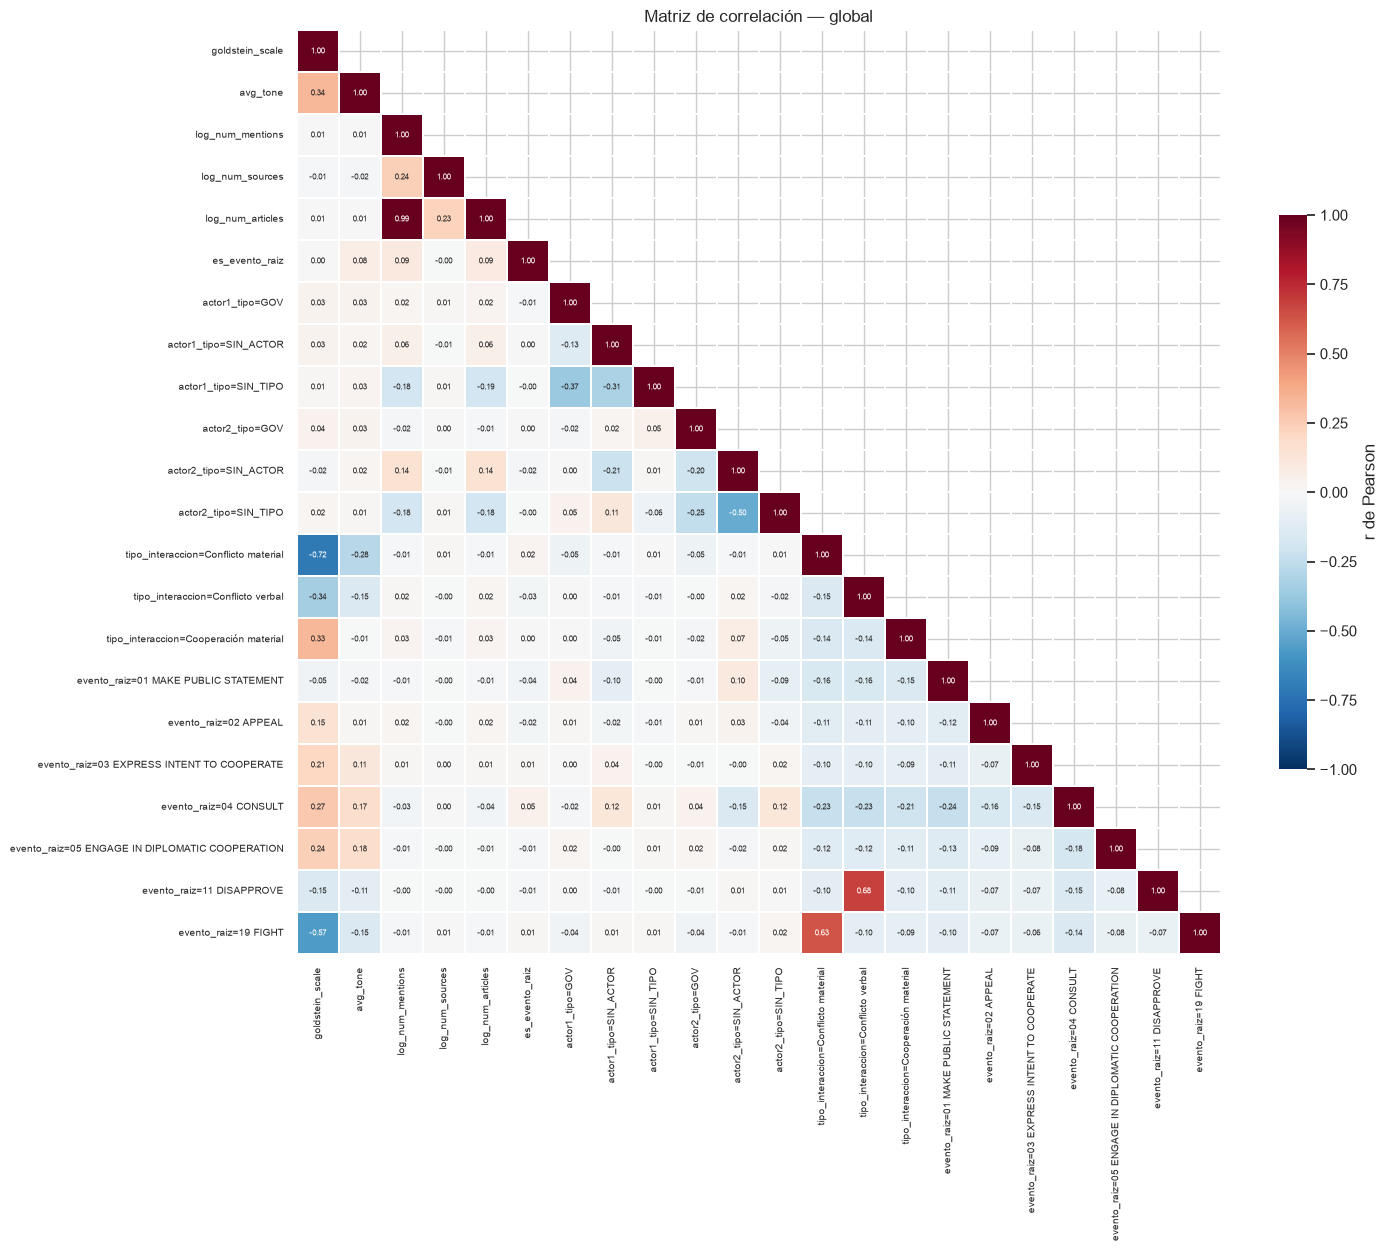

In [17]:
C_global = mv.correlaciones(X)
fig, ax = plt.subplots(figsize=(15, 12))
mv.heatmap_correlacion(C_global, "Matriz de correlación — global", ax=ax, anotar=True);

In [18]:
mv.pares_correlacionados(C_global, k=15).round(3)

,var_a,var_b,r
0,log_num_mentions,log_num_articles,0.993
1,goldstein_scale,tipo_interaccion=Conflicto material,-0.717
2,tipo_interaccion=Conflicto verbal,evento_raiz=11 DISAPPROVE,0.680
3,tipo_interaccion=Conflicto material,evento_raiz=19 FIGHT,0.627
4,goldstein_scale,evento_raiz=19 FIGHT,-0.565
5,actor2_tipo=SIN_ACTOR,actor2_tipo=SIN_TIPO,-0.503
6,actor1_tipo=GOV,actor1_tipo=SIN_TIPO,-0.367
7,goldstein_scale,tipo_interaccion=Conflicto verbal,-0.343
8,goldstein_scale,avg_tone,0.335
9,goldstein_scale,tipo_interaccion=Cooperación material,0.331


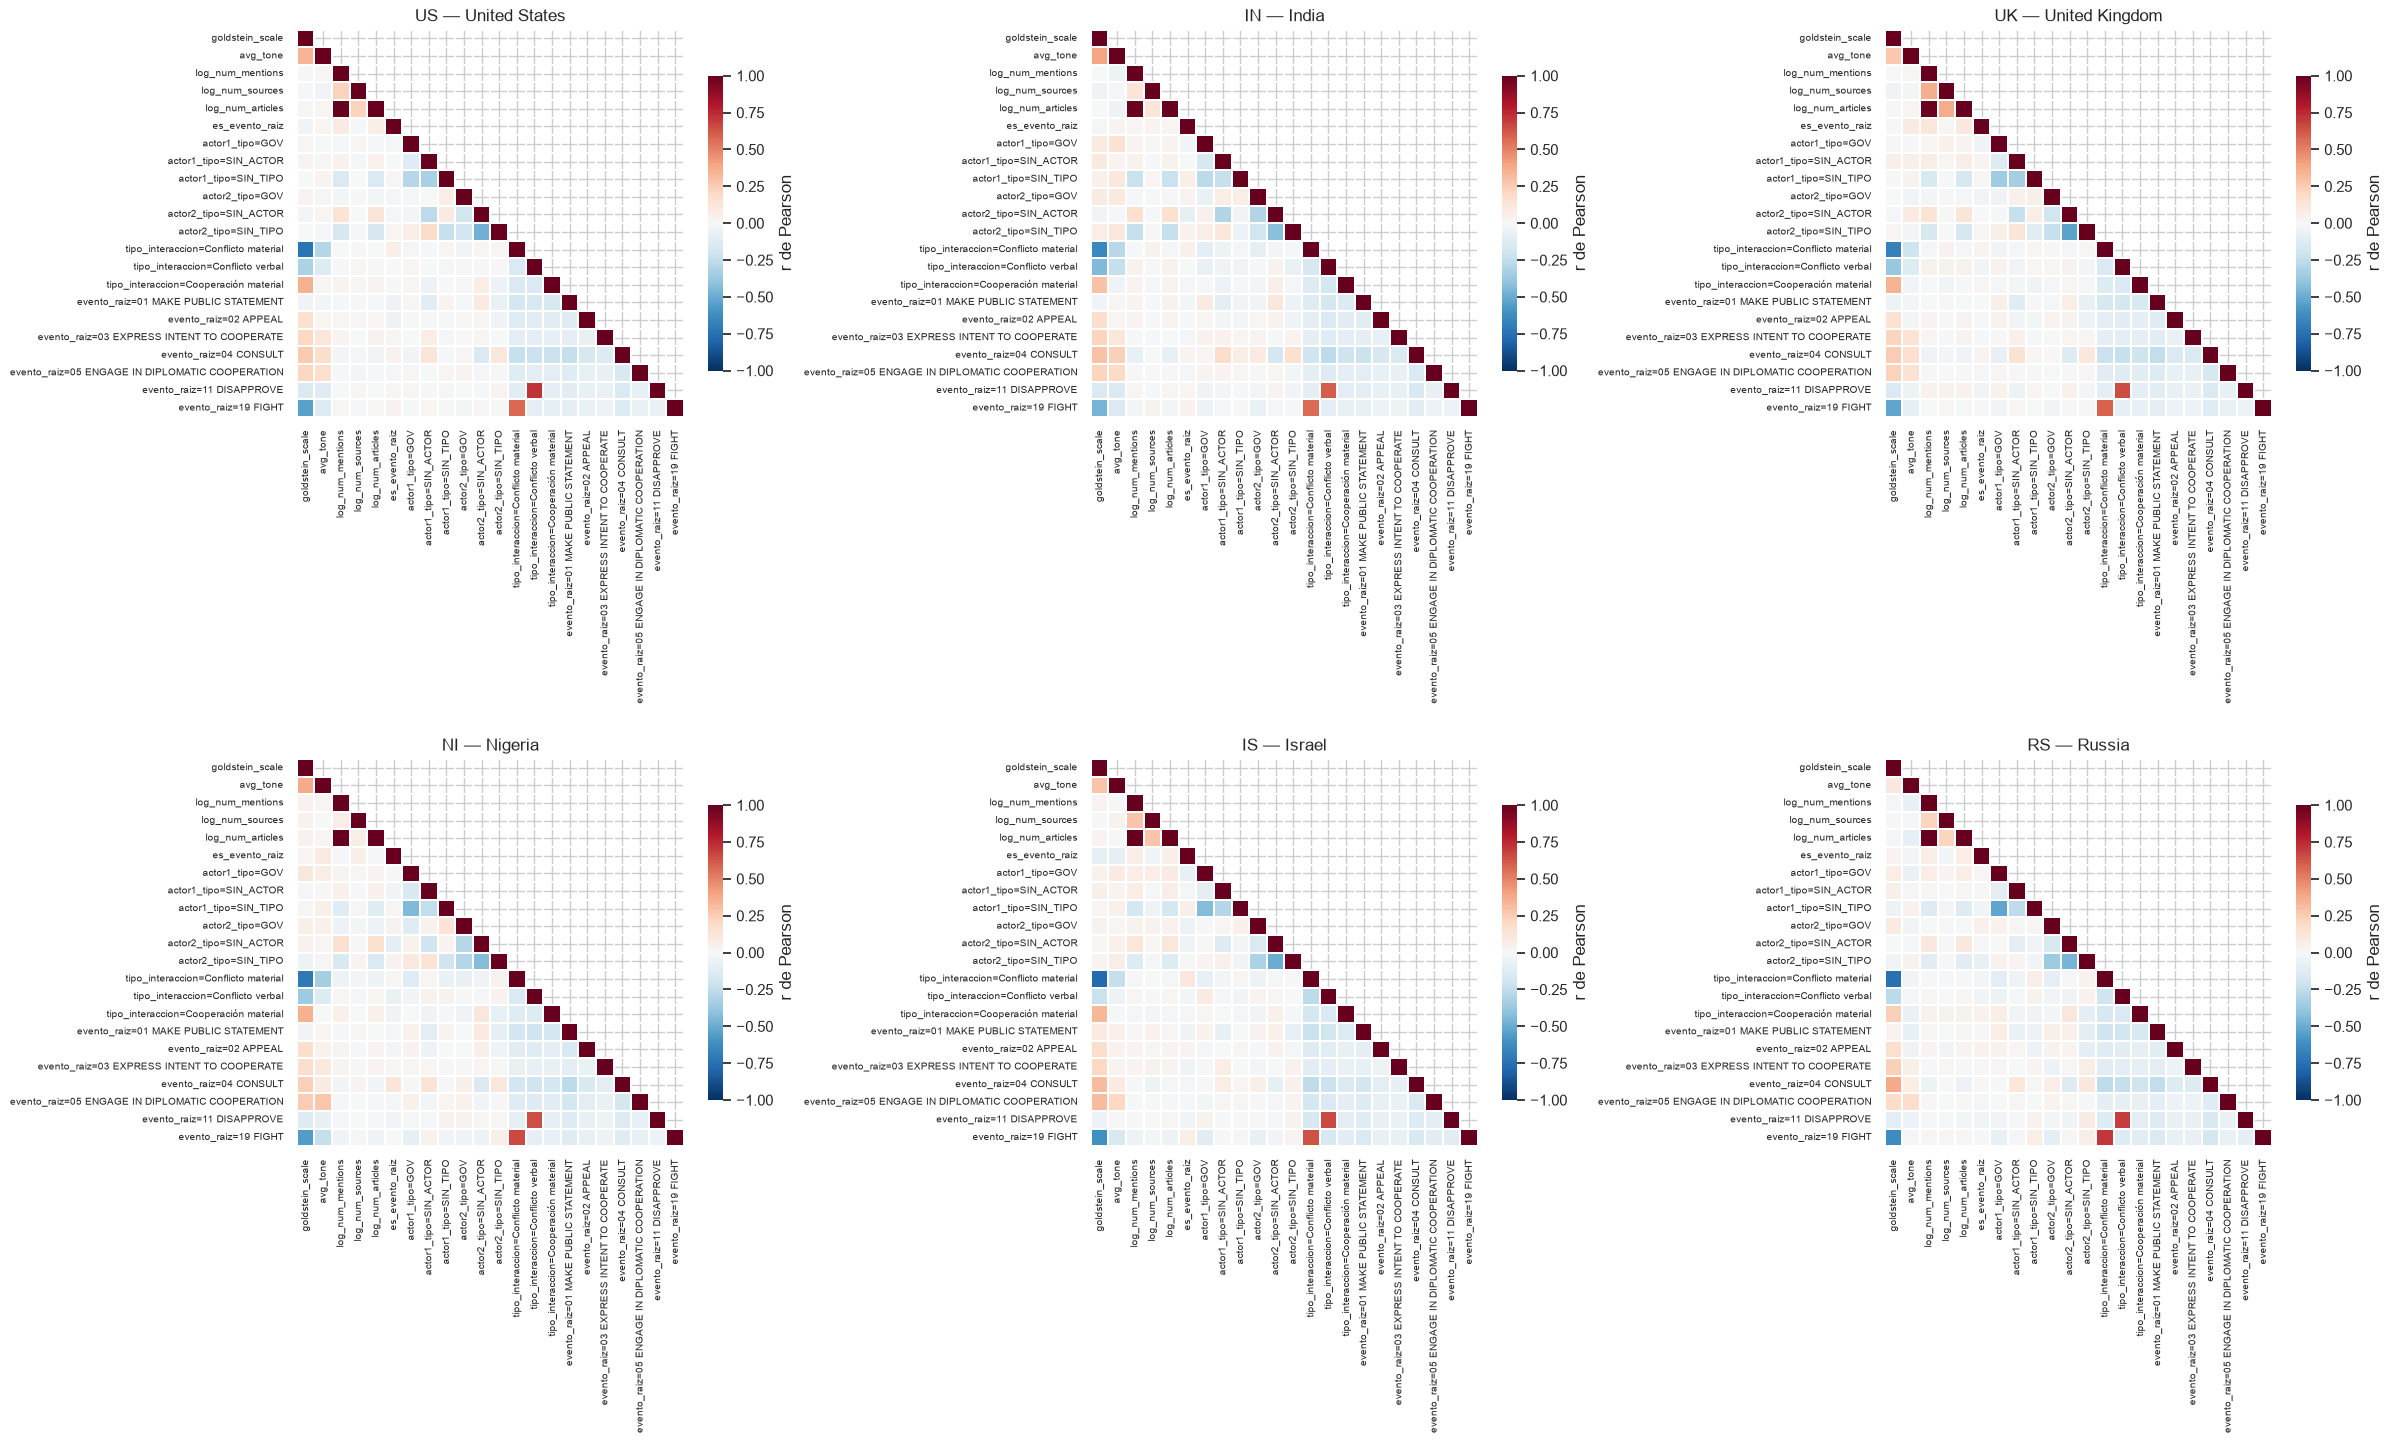

In [19]:
paises_corr = paises[:6]
fig, axes = plt.subplots(2, 3, figsize=(24, 15))
for ax, p in zip(axes.flat, paises_corr):
    mv.heatmap_correlacion(mv.correlaciones(X[(grupo == p).to_numpy()]), f"{p} — {nombres_pais.get(p, p)}", ax=ax)
plt.tight_layout()

In [20]:
# Misma asociación medida dentro de cada país
pd.concat([
    mv.comparar_correlaciones(X, grupo, paises, "goldstein_scale", "avg_tone"),
    mv.comparar_correlaciones(X, grupo, paises, "log_num_sources", "log_num_articles"),
    mv.comparar_correlaciones(X, grupo, paises, "goldstein_scale", "tipo_interaccion=Conflicto material"),
], axis=1)

,"r(goldstein_scale, avg_tone)","r(log_num_sources, log_num_articles)","r(goldstein_scale, tipo_interaccion=Conflicto material)"
GLOBAL,0.335,0.234,-0.717
US,0.340,0.232,-0.729
IN,0.397,0.127,-0.643
UK,0.272,0.374,-0.677
NI,0.377,0.066,-0.712
IS,0.282,0.284,-0.774
RS,0.107,0.221,-0.744
CA,0.280,0.261,-0.643
CH,0.252,0.258,-0.612
IR,0.295,0.182,-0.733


In [21]:
# Diferencia entre la correlación de cada país y la global: dónde cambia la estructura
dif = {p: (mv.correlaciones(X[(grupo == p).to_numpy()]) - C_global).abs().stack().mean() for p in paises}
pd.Series(dif, name="|r_país − r_global| medio").sort_values(ascending=False).round(3).to_frame()

,|r_país − r_global| medio
SA,0.038
AS,0.038
RS,0.033
PK,0.031
IS,0.028
IR,0.028
CH,0.026
IN,0.026
CA,0.025
NI,0.025


> 🧭 **Guía (a completar por el equipo)** — la consigna pide que en este punto la IA no dé la respuesta directa.

**Pregunta 3 — Estructura de correlación.**

- Identifiquen los bloques de variables muy correlacionadas en el mapa global. ¿Alguno es **redundancia por construcción** (dos medidas de lo mismo) y no un hallazgo sobre las noticias? ¿Qué harían con esas variables?
- `goldstein_scale` y las indicadoras de conflicto: ¿la correlación describe una asociación empírica o una definición del codebook? (Pista: ¿de dónde sale el valor de Goldstein de cada evento?)
- `goldstein_scale` vs `avg_tone`: una mide el impacto teórico del tipo de acción, la otra el tono del texto. ¿Qué indica que su correlación sea positiva pero moderada? ¿En qué país se debilita más y qué hipótesis plantearían?
- Correlaciones negativas entre indicadoras de una **misma** variable (p. ej. `SIN_ACTOR` vs `SIN_TIPO`): ¿son una asociación real o una consecuencia de que las categorías sean mutuamente excluyentes?
- ¿Qué país tiene la estructura de correlación más distinta a la global? ¿Coincide con los países más distantes en 2.1?


✍️ **Interpretación del equipo:** 
- Se distinguen tres bloques: menciones y artículos, con una correlación de 0,99; Goldstein con conflicto material y FIGHT; y conflicto verbal con DISAPPROVE. El primero es redundancia por construcción, porque cada artículo que menciona el evento suma al menos una mención y ambas variables miden prácticamente lo mismo. Los otros dos también provienen de cómo GDELT codifica los eventos. Lo razonable es conservar una sola de las variables de conteo o asumir que el ACP las va a fusionar en una misma componente; en las distancias, Mahalanobis corrige ese doble conteo.
- Es una definición. GDELT asigna el valor de Goldstein a partir del código CAMEO, así que un evento de FIGHT o de conflicto material recibe siempre un Goldstein muy negativo. La correlación de −0,72 con conflicto material refleja la tabla de puntajes y no dice nada sobre las noticias, por lo que no debe interpretarse como un hallazgo.
- Las dos medidas tienen orígenes independientes: una viene del tipo de acción y la otra del texto del artículo. Una correlación de 0,34 indica que coinciden en la dirección, ya que los eventos cooperativos se cuentan con un tono algo más positivo, pero que el tono tiene mucha variación propia, que depende del medio y del encuadre. La relación se debilita más en Rusia, con 0,11. La hipótesis es que su cobertura tiene un tono negativo casi independiente del tipo de acción: incluso las consultas o los actos de cooperación se narran en un contexto de guerra y sanciones.
- No. Son consecuencia de que las categorías se excluyen mutuamente: si el actor 2 no existe, no puede ser a la vez un actor sin tipo. Cuanto más frecuentes son ambas categorías, más negativa resulta la correlación, así que no deben interpretarse como una asociación sustantiva.
- Los más distintos son Arabia Saudita y Australia, seguidos de Rusia y Pakistán. Estados Unidos y Reino Unido son los más parecidos, en parte porque Estados Unidos pesa mucho en el total global. Esto coincide bastante con los países más distantes de 2.1, sobre todo Australia y Rusia, aunque por razones distintas. En Australia, las fuentes se correlacionan mucho más con las menciones y los artículos (en torno a 0,6, frente a 0,24 a nivel global), es decir, sus eventos con mucha cobertura llegan a muchos medios distintos. En Rusia cambia la relación entre el tono y el tipo de interacción. En Pakistán y Nigeria, las fuentes casi no se relacionan con la cantidad de artículos, lo que sugiere una cobertura concentrada en pocos medios que publican mucho.

# 3) Reducción de dimensionalidad: ACP

## 3.1 Ajuste del modelo

Las variables se **estandarizan** (media 0, desvío 1) y se ajusta el ACP sobre la matriz completa
(`src/acp.py::ajustar_acp`). Con datos estandarizados el ACP equivale a diagonalizar la **matriz de correlación**,
por lo que la varianza total es igual a p (cantidad de variables) y cada autovalor se lee como "cuántas variables originales vale" esa componente.

In [22]:
res = acp.ajustar_acp(X)
print(f"Variables: {len(res.columnas)} | varianza total = {res.varianza['autovalor'].sum():.2f}")
res.varianza

Variables: 22 | varianza total = 22.00


,autovalor,pct_varianza,pct_acumulado
PC1,2.693,12.243,12.243
PC2,2.301,10.460,22.702
PC3,1.877,8.531,31.234
PC4,1.748,7.944,39.178
PC5,1.380,6.273,45.451
PC6,1.217,5.532,50.983
PC7,1.170,5.318,56.301
PC8,1.151,5.231,61.532
PC9,1.105,5.022,66.554
PC10,1.092,4.963,71.517


## 3.2 Varianza explicada y gráfico de sedimentación

,n_componentes
Kaiser (autovalor > 1),12
Varianza acumulada >= 80%,12
"Varianza media (Jolliffe, autovalor > 0.7)",15


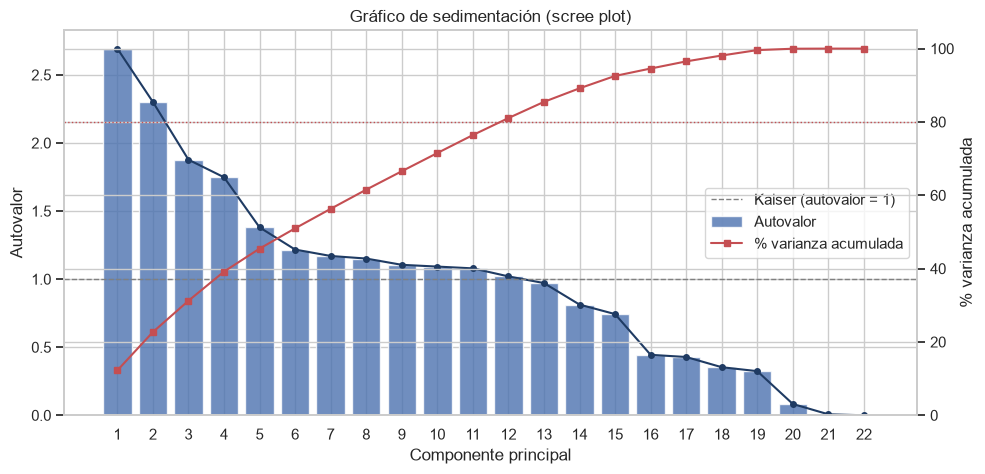

In [23]:
acp.scree_plot(res, cfg.acp["varianza_objetivo"])
acp.criterios_componentes(res, cfg.acp["varianza_objetivo"]).to_frame()

> 🧭 **Guía (a completar por el equipo)** — la consigna pide que en este punto la IA no dé la respuesta directa.

- ¿Dónde ven el "codo" del scree plot? ¿Coincide con lo que sugieren Kaiser y el 80 % de varianza acumulada?
- Varias componentes tienen autovalor apenas mayor que 1. Comparadas con una variable estandarizada (autovalor = 1), ¿están resumiendo información o representan casi una sola variable? (Miren sus cargas en 3.3.)
- ¿Por qué un ACP sobre muchas indicadoras binarias casi independientes comprime "mal" la varianza? ¿Qué esperarían si solo usaran las 5 variables continuas?
- ¿Por qué el último autovalor es ≈ 0? (conecten con la guía de 1.3)
- Fijen `N_COMPONENTES` en la celda siguiente y **justifiquen** la elección.


✍️ **Interpretación del equipo:** 
- El codo está después de la quinta componente. Las primeras cinco tienen autovalores que bajan de 2,7 a 1,4; a partir de ahí se forma una meseta casi plana de componentes con autovalor apenas mayor que 1, hasta la decimotercera. Kaiser y el criterio del 80 % coinciden entre sí en 12 componentes, pero no con el codo. Esa diferencia se explica porque ambos criterios cuentan como "útiles" las componentes de la meseta, que en realidad aportan poco cada una.
- Representan casi una sola variable. Una variable estandarizada tiene varianza 1, así que una componente con autovalor 1,1 no resume mucho más que una columna original. Sus cargas lo confirman: cada componente de la meseta está dominada por una o dos dummies (ENGAGE IN DIPLOMATIC COOPERATION en la séptima, EXPRESS INTENT TO COOPERATE en la décima, APPEAL en la undécima, es_evento_raiz en la decimotercera). No describen una dimensión latente del ecosistema de noticias, sino categorías individuales que el ACP no logró combinar con otras.
- El ACP comprime aprovechando las correlaciones entre variables. Las dummies de categorías distintas están poco correlacionadas entre sí y, una vez estandarizadas, cada una aporta una unidad de varianza que no comparte con nadie. Por eso cada una termina necesitando su propia componente, y las dos primeras explican apenas un 23 % del total. Con solo las cinco continuas, la compresión es mucho mejor: la primera componente reúne menciones y artículos (la atención mediática), la segunda reúne Goldstein y tono (el carácter cooperativo o conflictivo), y entre las dos explican cerca del 69 % de la varianza. Con tres componentes se supera el 86 %.
- Por la dependencia lineal exacta vista en 1.3: la QuadClass se define a partir del código raíz, y las dummies de los códigos 01 a 05 reconstruyen exactamente la cooperación verbal, que es la referencia de tipo_interaccion. Esa combinación no tiene varianza propia, así que la última componente queda vacía. El penúltimo autovalor también es casi nulo, en este caso por la correlación de 0,99 entre menciones y artículos.
- Retenemos cinco componentes. Coinciden con el codo del scree plot y son las únicas que representan combinaciones interpretables de varias variables: conflicto contra cooperación, atención mediática, conflicto verbal y las dos dimensiones de tipo de actor. Las componentes de la meseta, aunque superan el criterio de Kaiser, solo reproducen dummies individuales. El costo es que las cinco explican alrededor del 45 % de la varianza, una proporción baja pero esperable en una matriz dominada por variables binarias poco correlacionadas.

In [24]:
# Decisión del equipo: cantidad de componentes retenidas (por defecto, el criterio de Kaiser).
N_COMPONENTES = int(acp.criterios_componentes(res)["Kaiser (autovalor > 1)"])
print(f"Componentes retenidas: {N_COMPONENTES} -> {res.varianza['pct_acumulado'].iloc[N_COMPONENTES - 1]:.1f}% de la varianza")

Componentes retenidas: 12 -> 81.1% de la varianza


## 3.3 Interpretación de componentes (cargas)

Cargas = autovector × √autovalor: con datos estandarizados son la **correlación entre cada variable y la componente**,
así que son comparables entre variables y entre componentes.

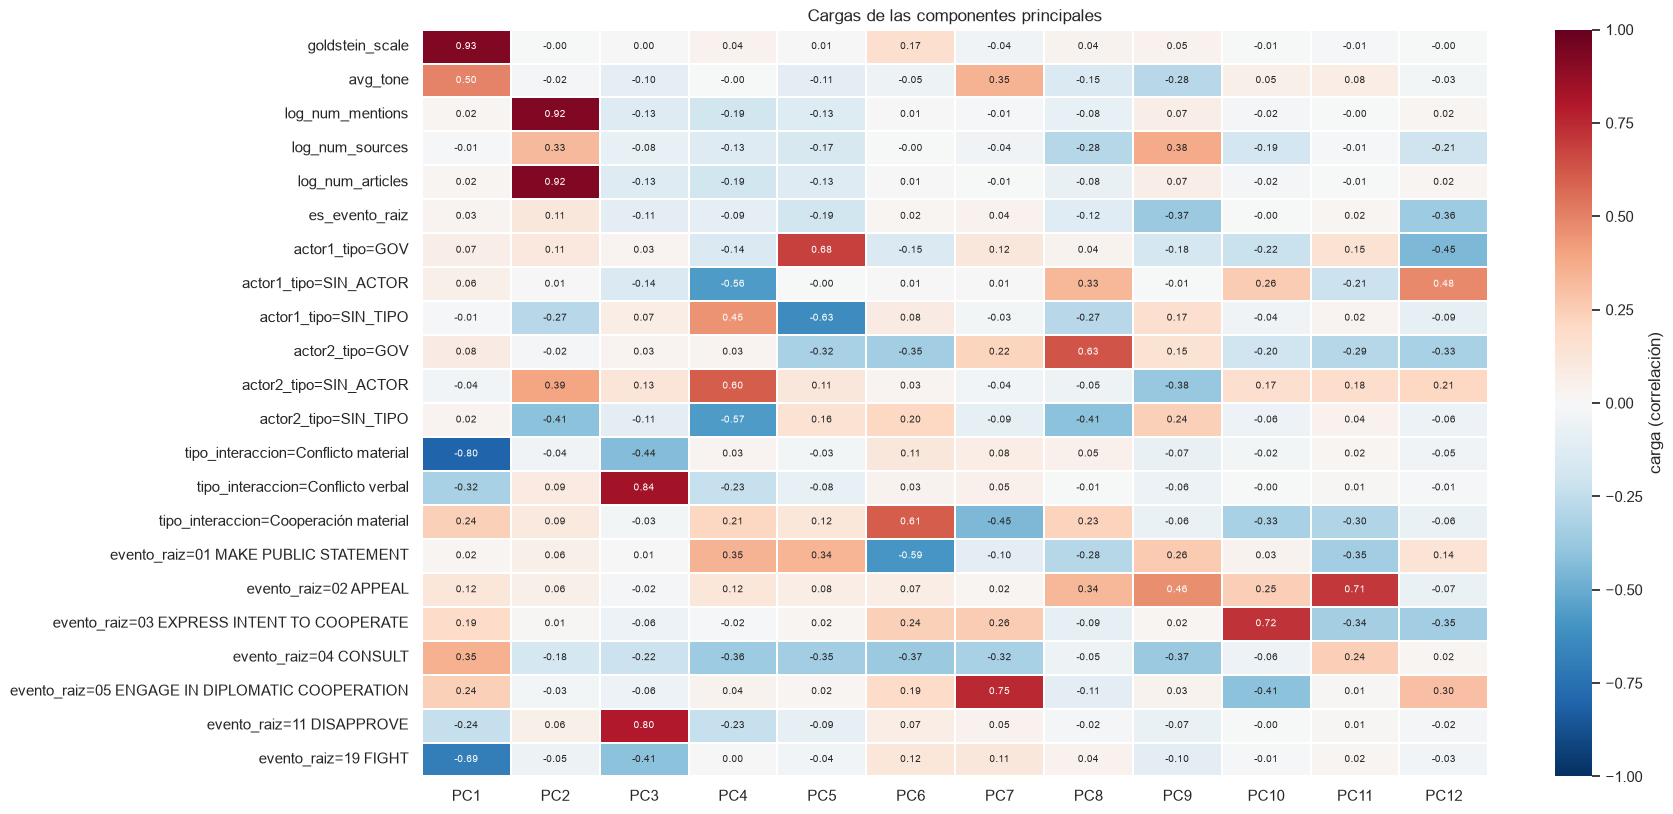

In [25]:
cargas = res.cargas(N_COMPONENTES)
acp.heatmap_cargas(cargas);

In [26]:
acp.cargas_principales(cargas, k=5)

componente                                  PC1                                                    PC10                                               PC11  \
                                       variable  carga                                         variable  carga                                    variable   
rank                                                                                                                                                         
1                               goldstein_scale  0.929       evento_raiz=03 EXPRESS INTENT TO COOPERATE  0.725                       evento_raiz=02 APPEAL   
2           tipo_interaccion=Conflicto material -0.797  evento_raiz=05 ENGAGE IN DIPLOMATIC COOPERATION -0.407        evento_raiz=01 MAKE PUBLIC STATEMENT   
3                          evento_raiz=19 FIGHT -0.692            tipo_interaccion=Cooperación material -0.327  evento_raiz=03 EXPRESS INTENT TO COOPERATE   
4                                      avg_tone  0.498                            actor1_tipo=SIN_ACTOR  0.256       tipo_interaccion=Cooperación material   
5                        evento_raiz=04 CONSULT  0.353                            evento_raiz=02 APPEAL  0.247                             actor2_tipo=GOV   

componente                                               PC12                           PC2                                         PC3         \
            carga                                    variable  carga               variable  carga                             variable  carga   
rank                                                                                                                                             
1           0.707                       actor1_tipo=SIN_ACTOR  0.482       log_num_articles  0.924    tipo_interaccion=Conflicto verbal   0.84   
2          -0.349                             actor1_tipo=GOV -0.452       log_num_mentions  0.924            evento_raiz=11 DISAPPROVE  0.802   
3          -0.341                              es_evento_raiz -0.363   actor2_tipo=SIN_TIPO -0.413  tipo_interaccion=Conflicto material -0.437   
4            -0.3  evento_raiz=03 EXPRESS INTENT TO COOPERATE  -0.35  actor2_tipo=SIN_ACTOR  0.393                 evento_raiz=19 FIGHT  -0.41   
5          -0.286                             actor2_tipo=GOV -0.325        log_num_sources  0.326               evento_raiz=04 CONSULT -0.217   

componente                     PC4                                          PC5                                                PC6         \
                          variable  carga                              variable  carga                                    variable  carga   
rank                                                                                                                                        
1            actor2_tipo=SIN_ACTOR  0.605                       actor1_tipo=GOV  0.681       tipo_interaccion=Cooperación material  0.608   
2             actor2_tipo=SIN_TIPO -0.569                  actor1_tipo=SIN_TIPO -0.626        evento_raiz=01 MAKE PUBLIC STATEMENT -0.593   
3            actor1_tipo=SIN_ACTOR -0.563                evento_raiz=04 CONSULT -0.349                      evento_raiz=04 CONSULT -0.373   
4             actor1_tipo=SIN_TIPO   0.45  evento_raiz=01 MAKE PUBLIC STATEMENT  0.336                             actor2_tipo=GOV  -0.35   
5           evento_raiz=04 CONSULT -0.363                       actor2_tipo=GOV -0.324  evento_raiz=03 EXPRESS INTENT TO COOPERATE  0.237   

componente                                              PC7                                          PC8                            PC9         
                                                   variable  carga                              variable  carga                variable  carga  
rank                                                                                                                                            
1 

> 🧭 **Guía (a completar por el equipo)** — la consigna pide que en este punto la IA no dé la respuesta directa.

- Para cada componente, miren las 3–5 variables con mayor |carga| **y su signo**. ¿Qué tienen en común las que cargan en el mismo sentido? ¿Qué las opone a las de signo contrario?
- PC1: ¿qué eje del ecosistema de noticias separa? (Pista: miren juntos Goldstein, tono y las indicadoras de conflicto.)
- PC2: ¿describe *qué pasa* en el evento o *cuánta atención* recibe?
- Algunas componentes oponen indicadoras de una misma variable (p. ej. `SIN_ACTOR` vs `SIN_TIPO`). ¿Es una dimensión del fenómeno o un efecto de la codificación?
- Completen el diccionario de la celda siguiente con un nombre conceptual por componente.


✍️ **Interpretación del equipo:** 
- En la primera componente, Goldstein, el tono y CONSULT cargan en positivo, frente a conflicto material y FIGHT, que cargan en negativo. Opone la cooperación al conflicto violento. La segunda reúne menciones, artículos y, en menor medida, fuentes, todas con signo positivo: mide el volumen de cobertura. La tercera opone conflicto verbal y DISAPPROVE, positivos, a conflicto material y FIGHT, negativos: separa el conflicto expresado en palabras del conflicto en hechos. La cuarta opone los eventos sin actor 2 y con actor 1 sin tipo, asociados a declaraciones públicas, a los eventos con dos actores, asociados a consultas. La quinta opone un actor 1 gubernamental a un actor 1 identificado solo por su país.
- Separa la cooperación del conflicto material. Goldstein carga 0,93 y conflicto material −0,80, así que la componente ordena los eventos según su carácter cooperativo u hostil. El tono acompaña en el mismo sentido con una carga más moderada, de 0,50, lo que indica que el texto refleja ese eje pero con una variación propia.
- Describe cuánta atención recibe. Menciones y artículos cargan 0,92 y casi no se relacionan con Goldstein, el tono ni el tipo de interacción, que tienen cargas cercanas a 0. Esto confirma que la cobertura de un evento es independiente de si es cooperativo o conflictivo. La carga secundaria de las dummies del actor 2 sugiere que los eventos sin un actor 2 identificado tienden a recibir algo más de cobertura.
- Es en parte un efecto de la codificación. Como SIN_ACTOR y SIN_TIPO se excluyen mutuamente, siempre van a tener signos opuestos. Pero la cuarta componente no se limita a eso: combina la ausencia de actor 2 con el actor 1 sin tipo y con las declaraciones públicas, frente a las consultas. Así captura una diferencia real entre eventos unilaterales (un Estado que declara algo) y eventos bilaterales (dos partes que interactúan). La oposición dentro de la variable es mecánica, pero la combinación con otras variables le da sentido.
- La primera es cooperación frente a conflicto; la segunda, atención mediática; la tercera, conflicto verbal frente a conflicto material; la cuarta, eventos unilaterales frente a bilaterales; y la quinta, protagonismo gubernamental.

In [27]:
# Nombre conceptual de cada componente retenida (a completar por el equipo)
NOMBRES_COMPONENTES = {f"PC{i + 1}": "¿?" for i in range(N_COMPONENTES)}
NOMBRES_COMPONENTES

{'PC1': '¿?',
 'PC2': '¿?',
 'PC3': '¿?',
 'PC4': '¿?',
 'PC5': '¿?',
 'PC6': '¿?',
 'PC7': '¿?',
 'PC8': '¿?',
 'PC9': '¿?',
 'PC10': '¿?',
 'PC11': '¿?',
 'PC12': '¿?'}

## 3.4 Biplot PC1 vs PC2 y valores atípicos multivariantes

Se dibuja una muestra aleatoria de eventos (`config.toml → muestra_biplot`) coloreados por tipo de interacción, con las
flechas de las 10 variables de mayor carga en el plano. Como criterio de atipicidad multivariante se usa el
**T² de Hotelling** en el subespacio de las componentes retenidas, $T^2_i = \sum_{j=1}^{k} z_{ij}^2/\lambda_j$,
contra el cuantil $\chi^2_{k}(0{,}999)$.

Umbral χ²(12; 0.999) = 32.9 | outliers: 720 (0.68% de los eventos)


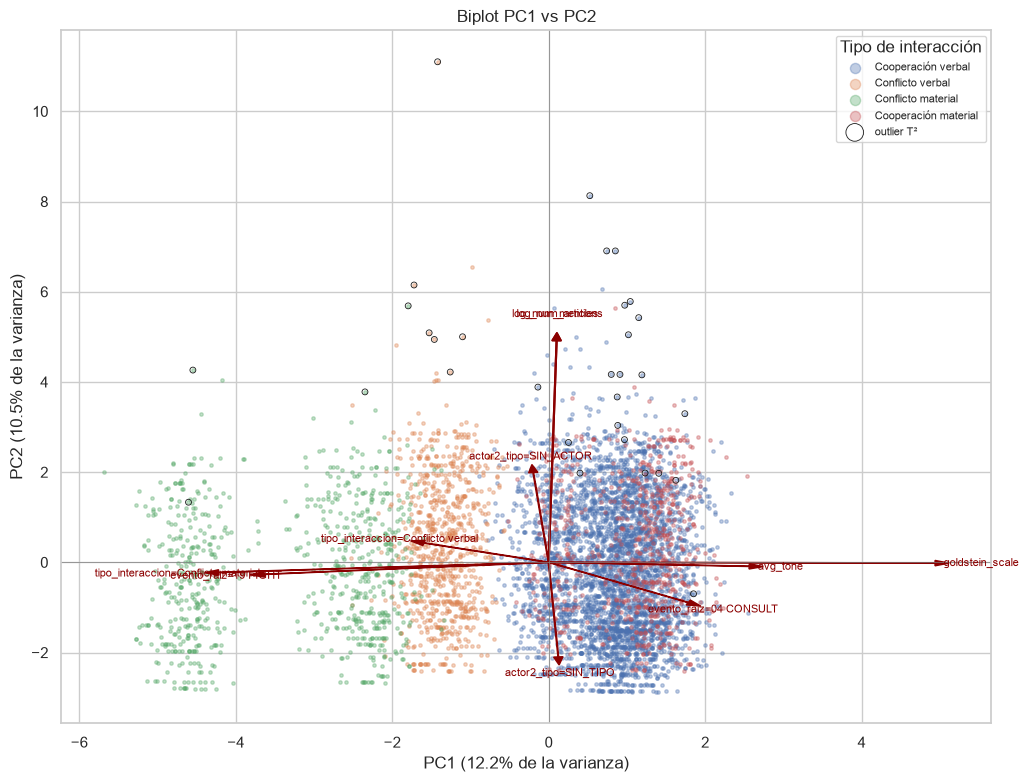

In [28]:
t2 = acp.outliers_t2(res, N_COMPONENTES, cfg.acp["alfa_outliers"])
es_outlier = t2 > t2.attrs["umbral"]
print(f"Umbral χ²({N_COMPONENTES}; 0.999) = {t2.attrs['umbral']:.1f} | "
      f"outliers: {es_outlier.sum():,} ({100 * es_outlier.mean():.2f}% de los eventos)")

color = eventos.set_index("global_event_id").loc[X.index, "tipo_interaccion"].rename("Tipo de interacción")
acp.biplot(res, color=color, n_muestra=cfg.acp["muestra_biplot"], outliers=t2, semilla=cfg.acp["semilla"]);

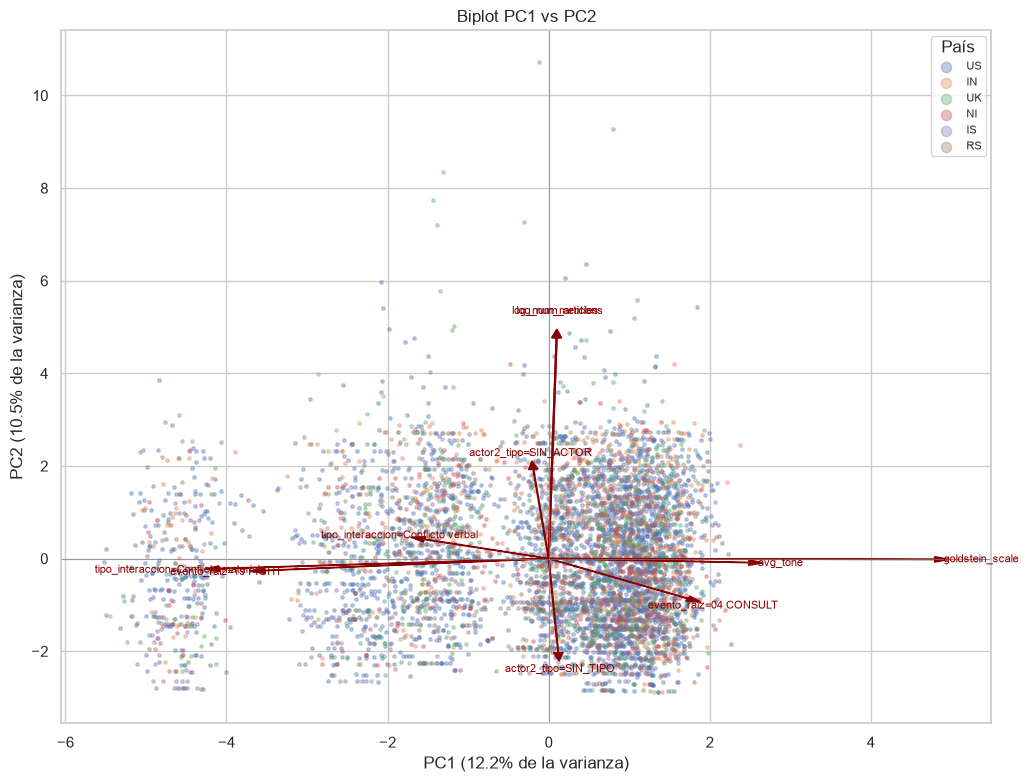

In [29]:
# Biplot coloreado por país (solo los 6 países principales) para ver si la geografía separa grupos
mask = grupo.isin(paises[:6]).to_numpy()
sub = acp.ResultadoACP(res.pca, res.scaler, res.scores[mask], res.varianza, res.columnas)
acp.biplot(sub, color=grupo[mask].rename("País"), n_muestra=cfg.acp["muestra_biplot"], semilla=cfg.acp["semilla"]);

In [30]:
# Perfil de los outliers frente al resto
ev_idx = eventos.set_index("global_event_id").loc[X.index]
comparacion = pd.DataFrame({
    "outliers": ev_idx[es_outlier.to_numpy()][["goldstein_scale", "avg_tone", "num_mentions", "num_sources", "num_articles"]].median(),
    "resto": ev_idx[~es_outlier.to_numpy()][["goldstein_scale", "avg_tone", "num_mentions", "num_sources", "num_articles"]].median(),
}).round(2)
display(comparacion.rename_axis("mediana"))

top = t2.sort_values(ascending=False).head(10).index
ev_idx.loc[top, ["pais_accion", "tipo_interaccion", "evento_raiz", "actor1_code", "actor2_code",
                 "goldstein_scale", "avg_tone", "num_mentions", "num_sources", "num_articles"]].assign(T2=t2.loc[top].round(1))

,outliers,resto
mediana,,
goldstein_scale,1.90,1.90
avg_tone,-2.31,-1.97
num_mentions,21.00,4.00
num_sources,5.00,1.00
num_articles,18.00,4.00


,pais_accion,tipo_interaccion,evento_raiz,actor1_code,actor2_code,goldstein_scale,avg_tone,num_mentions,num_sources,num_articles,T2
global_event_id,,,,,,,,,,,
1326338682,MO,Conflicto material,19 FIGHT,ESP,MAR,-9.5,-0.898876,140,14,140,190.7
1326424286,SA,Cooperación verbal,05 ENGAGE IN DIPLOMATIC COOPERATION,USA,SAU,3.5,-2.923977,130,13,130,189.5
1326403496,IS,Cooperación verbal,01 MAKE PUBLIC STATEMENT,JUD,GOV,0.0,-4.749018,84,14,84,176.4
1326424301,SA,Conflicto material,19 FIGHT,USA,YEM,-10.0,-2.923977,104,13,104,175.7
1326403705,UK,Conflicto material,17 COERCE,REF,ISRGOV,-5.0,-4.749018,98,14,98,169.0
1326403515,KU,Cooperación verbal,01 MAKE PUBLIC STATEMENT,KWT,SAUGOV,0.4,-4.749018,42,14,28,165.5
1326403442,IS,Cooperación verbal,01 MAKE PUBLIC STATEMENT,ISR,GOV,0.4,-4.749018,28,14,28,161.6
1326424088,DJ,Cooperación verbal,05 ENGAGE IN DIPLOMATIC COOPERATION,SAU,YEM,3.4,-2.923977,39,13,39,158.7
1326403729,KU,Cooperación verbal,01 MAKE PUBLIC STATEMENT,SAUGOV,NaN,0.0,-4.749018,84,14,84,154.9


**Lectura del biplot** (datos del 05/10/2026).

- **Agrupamiento por tipo de interacción sobre PC1:** las observaciones forman **bloques verticales** separados a lo largo de PC1.
  El conflicto material aparece en dos bloques en el extremo negativo (el de `FIGHT`, ≈ −4,5, y el resto del conflicto material, ≈ −2),
  el conflicto verbal en ≈ −1,5 y la cooperación verbal y material se superponen en 0 a 2. Las flechas de `goldstein_scale` y `avg_tone`
  apuntan al extremo positivo y las de conflicto material/`FIGHT` al negativo: PC1 ordena el eje **conflicto ↔ cooperación**.
  Los bloques son discretos porque Goldstein toma un valor fijo por código CAMEO.
- **PC2:** la dirección vertical la marcan los conteos (`log_num_mentions` y `log_num_articles`, flechas superpuestas) y, en sentido
  opuesto, `actor2_tipo=SIN_TIPO` frente a `SIN_ACTOR`. Las franjas horizontales dentro de cada bloque son los niveles discretos de
  cobertura (1, 2, 3… menciones) y de actor. Las flechas de conteos y las de Goldstein/conflicto son casi ortogonales: la **atención
  mediática** que recibe un evento es prácticamente independiente de si es cooperativo o conflictivo.
- **Geografía:** coloreado por país, los seis países principales se superponen por completo. Las diferencias de medias de 2.1 son
  desplazamientos de proporciones dentro de una nube común, no grupos separados.
- **Atípicos multivariantes:** con T² de Hotelling sobre las 12 componentes retenidas, 720 eventos (0,68 %) superan el umbral χ²₁₂(0,999) = 32,9.
  Casi todos están en la parte alta de PC2: su mediana es 21 menciones, 5 fuentes y 18 artículos frente a 4, 1 y 4 del resto, con el mismo
  Goldstein mediano. Los de mayor T² tienen 13–14 fuentes y comparten **exactamente el mismo tono** (p. ej. −4,749 o −2,924): son varios
  eventos que GDELT extrajo de **un mismo artículo muy replicado** (cobertura de Israel/Arabia Saudita/Yemen). No son errores de carga sino
  una propiedad del flujo: un solo texto viral genera varios "eventos" con cobertura extrema. Eso sugiere no eliminarlos, sino tenerlos en
  cuenta: los eventos no son observaciones independientes cuando provienen del mismo documento.

# 4) Respuestas a las preguntas de investigación

| Pregunta | Dónde se responde | Estado |
|---|---|---|
| 1. Perfil multivariante de eventos | 2.1 (vectores de medias, mapa de desvíos) | ✍️ a completar (guía en 2.1) |
| 2. Topología de cobertura mediática | 2.1 (distancias, dendrogramas, pares extremos) | Respondida en 2.1 |
| 3. Estructura de correlación | 2.2 (mapas de calor global y por país) | ✍️ a completar (guía en 2.2) |
| 4. Compresión del ecosistema de noticias | 3.2–3.4 (scree plot, cargas, biplot) | ✍️ elección de k y nombres de las componentes (guías en 3.2 y 3.3) |